In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("a")

a


In [19]:
df = pd.read_csv("./Data/train.csv")
print(df)
df.isnull().sum()

     PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                                                 ...     ...   ... 

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [20]:
df['Age'] = df['Age'].fillna(df['Age'].mean())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

In [21]:
# See first few ticket values
print(df['Ticket'].head())

# Check unique tickets
print(df['Ticket'].nunique())

print(df)


0           A/5 21171
1            PC 17599
2    STON/O2. 3101282
3              113803
4              373450
Name: Ticket, dtype: str
681
     PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex        Age  \
0                              Braund, Mr. Owen Harris    male  22.000000   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.000000   
2                               Heikkinen, Miss. Laina  female  26.000000   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.000000   
4                  

In [22]:
X = df.drop(['Ticket' , 'Cabin' , 'Survived' , 'PassengerId','Name'], axis=1)
y = df['Survived']

print("x is : ", X , "\n Y is :", y)

x is :       Pclass     Sex        Age  SibSp  Parch     Fare Embarked
0         3    male  22.000000      1      0   7.2500        S
1         1  female  38.000000      1      0  71.2833        C
2         3  female  26.000000      0      0   7.9250        S
3         1  female  35.000000      1      0  53.1000        S
4         3    male  35.000000      0      0   8.0500        S
..      ...     ...        ...    ...    ...      ...      ...
886       2    male  27.000000      0      0  13.0000        S
887       1  female  19.000000      0      0  30.0000        S
888       3  female  29.699118      1      2  23.4500        S
889       1    male  26.000000      0      0  30.0000        C
890       3    male  32.000000      0      0   7.7500        Q

[891 rows x 7 columns] 
 Y is : 0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64


In [23]:
from sklearn.preprocessing import StandardScaler,LabelEncoder
X['Sex'] = LabelEncoder().fit_transform(df['Sex']) 
X = pd.get_dummies(X, columns=['Embarked'], drop_first=True)

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)
print(X.columns)
print(X_scaled)

Index(['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_Q',
       'Embarked_S'],
      dtype='str')
[[ 0.82737724  0.73769513 -0.5924806  ... -0.50244517 -0.30756234
   0.61583843]
 [-1.56610693 -1.35557354  0.63878901 ...  0.78684529 -0.30756234
  -1.62380254]
 [ 0.82737724 -1.35557354 -0.2846632  ... -0.48885426 -0.30756234
   0.61583843]
 ...
 [ 0.82737724 -1.35557354  0.         ... -0.17626324 -0.30756234
   0.61583843]
 [-1.56610693  0.73769513 -0.2846632  ... -0.04438104 -0.30756234
  -1.62380254]
 [ 0.82737724  0.73769513  0.17706291 ... -0.49237783  3.25137334
  -1.62380254]]


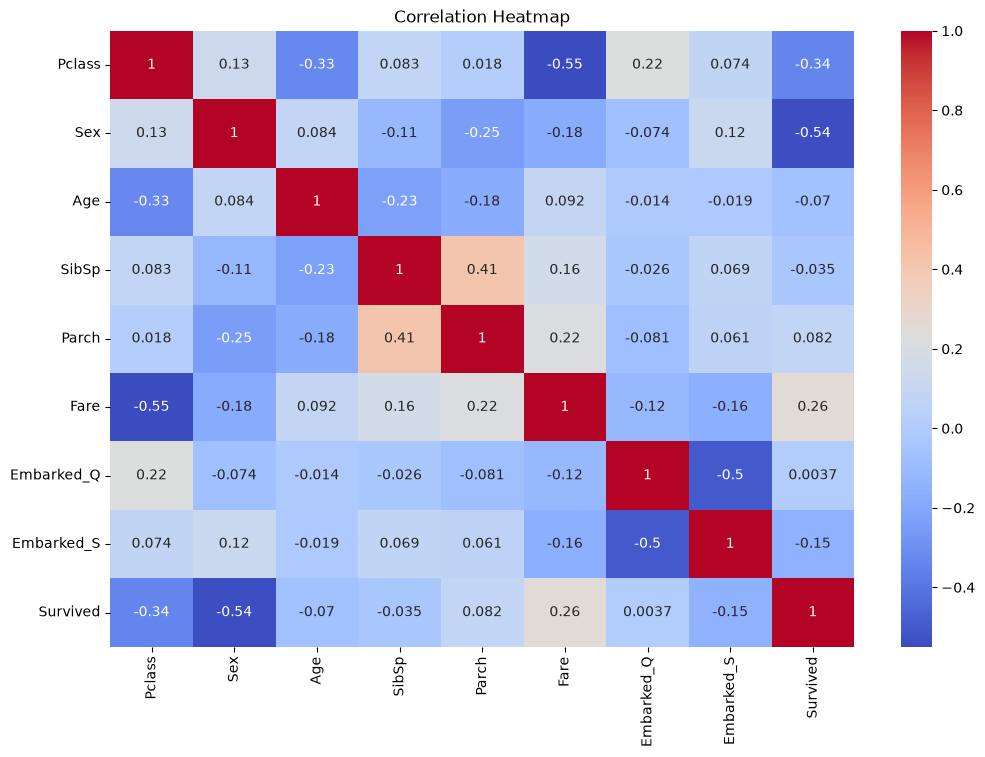

In [24]:
df_scaled = pd.DataFrame(X_scaled, columns=X.columns)
df_scaled['Survived'] = y

plt.figure(figsize=(12,8))
sns.heatmap(df_scaled.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

In [25]:
from sklearn.model_selection import train_test_split

# Assuming you already have X_scaled and y
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)


In [30]:
from tensorflow.keras.layers import Dropout

model = Sequential()
model.add(Dense(32, activation='relu', input_dim=X_train.shape[1]))
model.add(Dropout(0.3))  # drops 30% of neurons randomly
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(1, activation='sigmoid'))

In [31]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = (model.predict(X_test) > 0.5).astype("int32")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

6/6 [==============================] - 0s 4ms/step
[[109   1]
 [ 61   8]]
              precision    recall  f1-score   support

           0       0.64      0.99      0.78       110
           1       0.89      0.12      0.21        69

    accuracy                           0.65       179
   macro avg       0.77      0.55      0.49       179
weighted avg       0.74      0.65      0.56       179

